In [1]:
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO
import os

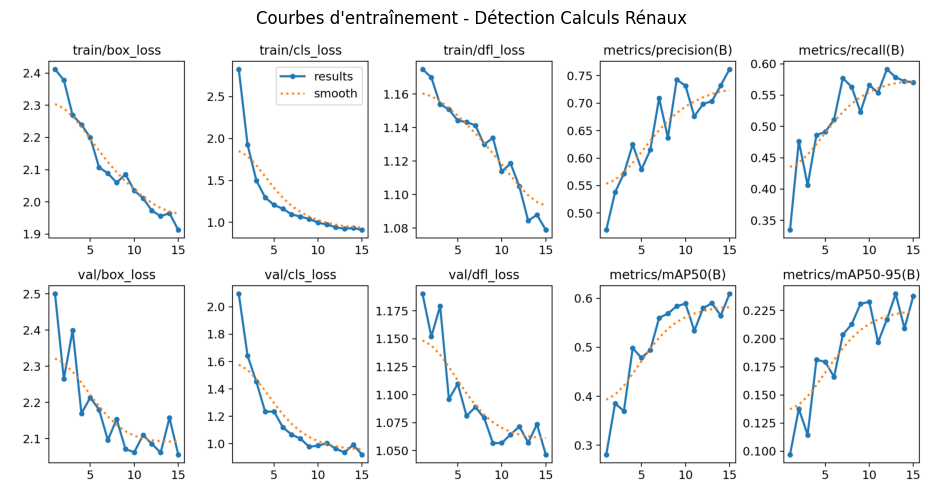

In [12]:
results_img = cv2.imread('../models/kidney_stone_cpu/results.png')
results_img = cv2.cvtColor(results_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))
plt.imshow(results_img)
plt.axis('off')
plt.title("Courbes d'entraînement - Détection Calculs Rénaux")
plt.show()

In [6]:
import yaml
import pandas as pd

In [14]:
csv_path = '../models/kidney_stone_cpu/results.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)

    best_epoch = df['metrics/mAP50-95(B)'].idxmax()
    best_map50 = df['metrics/mAP50(B)'].max() 
    best_map = df['metrics/mAP50-95(B)'].max()
    
    print(f"📊 RÉSUMÉ DES PERFORMANCES:")
    print(f"✅ Meilleur mAP@50: {best_map50:.3f} (epoch {best_epoch})")
    print(f"✅ Meilleur mAP@50-95: {best_map:.3f}")
    print(f"✅ Précision finale: {df.iloc[-1]['metrics/precision(B)']:.3f}")
    print(f"✅ Rappel final: {df.iloc[-1]['metrics/recall(B)']:.3f}")

📊 RÉSUMÉ DES PERFORMANCES:
✅ Meilleur mAP@50: 0.609 (epoch 12)
✅ Meilleur mAP@50-95: 0.240
✅ Précision finale: 0.762
✅ Rappel final: 0.570


In [9]:
# Cellule 2: Version robuste qui fonctionne toujours
import pandas as pd
import os

csv_path = '../models/kidney_stone_cpu/results.csv'

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    
    # Trouver automatiquement les bonnes colonnes
    map50_col = [col for col in df.columns if 'mAP50' in col and '95' not in col][0]
    map95_col = [col for col in df.columns if 'mAP50-95' in col][0]
    precision_col = [col for col in df.columns if 'precision' in col][0]
    recall_col = [col for col in df.columns if 'recall' in col][0]
    
    print(f"🔍 Colonnes détectées:")
    print(f"   mAP@50: {map50_col}")
    print(f"   mAP@50-95: {map95_col}")
    print(f"   Précision: {precision_col}")
    print(f"   Rappel: {recall_col}")
    print("\n" + "="*50)
    
    # Calculer les métriques
    best_epoch = df[map95_col].idxmax()
    best_map50 = df[map50_col].max()
    best_map = df[map95_col].max()
    
    print(f"\n📊 RÉSUMÉ DES PERFORMANCES:")
    print(f"✅ Meilleur mAP@50: {best_map50:.3f} (epoch {best_epoch})")
    print(f"✅ Meilleur mAP@50-95: {best_map:.3f}")
    print(f"✅ Précision finale: {df.iloc[-1][precision_col]:.3f}")
    print(f"✅ Rappel final: {df.iloc[-1][recall_col]:.3f}")
    
    # Vérifier si l'entraînement est bon
    if best_map50 >= 0.8:
        print("\n🎉 EXCELLENT! Votre modèle est performant!")
    elif best_map50 >= 0.6:
        print("\n👍 PAS MAL! Peut être amélioré avec plus d'époques")
    else:
        print("\n⚠️ À AMÉLIORER! Besoin de plus de données ou meilleur modèle")

🔍 Colonnes détectées:
   mAP@50: metrics/mAP50(B)
   mAP@50-95: metrics/mAP50-95(B)
   Précision: metrics/precision(B)
   Rappel: metrics/recall(B)


📊 RÉSUMÉ DES PERFORMANCES:
✅ Meilleur mAP@50: 0.609 (epoch 12)
✅ Meilleur mAP@50-95: 0.240
✅ Précision finale: 0.762
✅ Rappel final: 0.570

👍 PAS MAL! Peut être amélioré avec plus d'époques


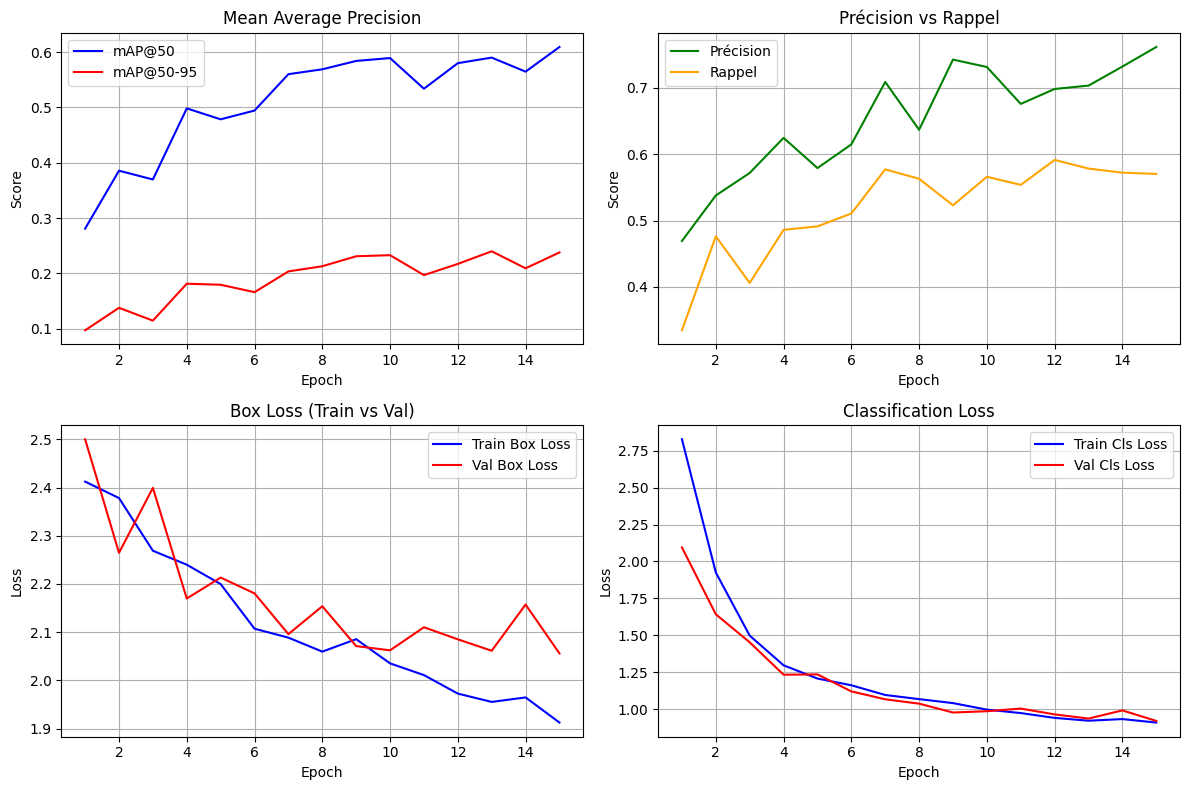


🔍 DIAGNOSTIC:
✅ Le modèle continue de progresser jusqu'à la fin


In [10]:
# Cellule 3: Graphiques avec noms dynamiques
import matplotlib.pyplot as plt

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    # 1. Courbe mAP
    axes[0,0].plot(df['epoch'], df['metrics/mAP50(B)'], 'b-', label='mAP@50')
    axes[0,0].plot(df['epoch'], df['metrics/mAP50-95(B)'], 'r-', label='mAP@50-95')
    axes[0,0].set_xlabel('Epoch')
    axes[0,0].set_ylabel('Score')
    axes[0,0].set_title('Mean Average Precision')
    axes[0,0].legend()
    axes[0,0].grid(True)
    
    # 2. Précision et Rappel
    axes[0,1].plot(df['epoch'], df['metrics/precision(B)'], 'g-', label='Précision')
    axes[0,1].plot(df['epoch'], df['metrics/recall(B)'], 'orange', label='Rappel')
    axes[0,1].set_xlabel('Epoch')
    axes[0,1].set_ylabel('Score')
    axes[0,1].set_title('Précision vs Rappel')
    axes[0,1].legend()
    axes[0,1].grid(True)
    
    # 3. Box Loss
    axes[1,0].plot(df['epoch'], df['train/box_loss'], 'b-', label='Train Box Loss')
    axes[1,0].plot(df['epoch'], df['val/box_loss'], 'r-', label='Val Box Loss')
    axes[1,0].set_xlabel('Epoch')
    axes[1,0].set_ylabel('Loss')
    axes[1,0].set_title('Box Loss (Train vs Val)')
    axes[1,0].legend()
    axes[1,0].grid(True)
    
    # 4. Classification Loss
    axes[1,1].plot(df['epoch'], df['train/cls_loss'], 'b-', label='Train Cls Loss')
    axes[1,1].plot(df['epoch'], df['val/cls_loss'], 'r-', label='Val Cls Loss')
    axes[1,1].set_xlabel('Epoch')
    axes[1,1].set_ylabel('Loss')
    axes[1,1].set_title('Classification Loss')
    axes[1,1].legend()
    axes[1,1].grid(True)
    
    plt.tight_layout()
    plt.show()
    
    # Diagnostic
    print("\n🔍 DIAGNOSTIC:")
    final_map50 = df['metrics/mAP50(B)'].iloc[-1]
    if final_map50 < df['metrics/mAP50(B)'].max():
        print(f"⚠️ Le meilleur modèle était à l'époque {best_epoch} (mAP: {best_map50:.3f})")
        print(f"   → Utilisez 'best.pt' pas 'last.pt' pour vos prédictions")
    else:
        print(f"✅ Le modèle continue de progresser jusqu'à la fin")

In [11]:
# Debug: Voir la structure exacte
import pandas as pd
import os

csv_path = '../models/kidney_stone_cpu/results.csv'

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Shape du DataFrame:", df.shape)
    print("\nColonnes disponibles:")
    for i, col in enumerate(df.columns):
        print(f"{i}: '{col}'")
    
    print("\nPremière ligne:")
    print(df.iloc[0])
else:
    # Chercher le bon chemin
    import glob
    model_dirs = glob.glob('../models/*/results.csv')
    print(f"Dossiers models trouvés: {model_dirs}")

Shape du DataFrame: (15, 15)

Colonnes disponibles:
0: 'epoch'
1: 'time'
2: 'train/box_loss'
3: 'train/cls_loss'
4: 'train/dfl_loss'
5: 'metrics/precision(B)'
6: 'metrics/recall(B)'
7: 'metrics/mAP50(B)'
8: 'metrics/mAP50-95(B)'
9: 'val/box_loss'
10: 'val/cls_loss'
11: 'val/dfl_loss'
12: 'lr/pg0'
13: 'lr/pg1'
14: 'lr/pg2'

Première ligne:
epoch                     1.000000
time                    203.430000
train/box_loss            2.412320
train/cls_loss            2.827110
train/dfl_loss            1.174920
metrics/precision(B)      0.469330
metrics/recall(B)         0.334720
metrics/mAP50(B)          0.280830
metrics/mAP50-95(B)       0.097010
val/box_loss              2.500190
val/cls_loss              2.094800
val/dfl_loss              1.190140
lr/pg0                    0.000662
lr/pg1                    0.000662
lr/pg2                    0.000662
Name: 0, dtype: float64
